## Análise Exploratória de Dados (EDA): 

### 1. Importando as libs e declarando alguns paths que os arquivos dos gráficos devem ser encaminhados:

In [49]:
from __future__ import annotations
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Detecta a raiz do projeto de forma robusta no Jupyter
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_CSV_PATH = PROJECT_ROOT / "data" / "raw" / "bbc-text.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# Verificação de segurança
print(f"Raiz do Projeto: {PROJECT_ROOT}")
print(f"Caminho do CSV:  {RAW_CSV_PATH}")
print(f"Arquivo existe?  {RAW_CSV_PATH.exists()}")

Raiz do Projeto: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction
Caminho do CSV:  c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\data\raw\bbc-text.csv
Arquivo existe?  True


### 2. Carregando o CSV

In [50]:
df = pd.read_csv(RAW_CSV_PATH)

# Engenharia de variáveis para análise exploratória
df["char_count"] = df["text"].astype(str).str.len()
df["word_count"] = df["text"].astype(str).apply(lambda t: len(t.split()))
df

,category,text,char_count,word_count
0,tech,tv future in the hands of viewers with home th...,4333,737
1,business,worldcom boss left books alone former worldc...,1842,300
2,sport,tigers wary of farrell gamble leicester say ...,1342,246
3,sport,yeading face newcastle in fa cup premiership s...,2176,341
4,entertainment,ocean s twelve raids box office ocean s twelve...,1579,260
...,...,...,...,...
2220,business,cars pull down us retail figures us retail sal...,1745,293
2221,politics,kilroy unveils immigration policy ex-chatshow ...,955,156
2222,entertainment,rem announce new glasgow concert us band rem h...,1648,301
2223,politics,how political squabbles snowball it s become c...,4684,858


### Análise Descritiva do Dataset

#### 1. Observação geral

In [51]:
print("===========================================================================================")
print(f"Total de observações (linhas): {len(df)}")
print(f"Variável-alvo: 'category' (Tipo: Categórica Nominal)")
print(f"Variável preditora: 'text' (Tipo: Texto em Linguagem Natural)")
print(f"Valores nulos/ausentes:\n{df.isnull().sum()}")
print("===========================================================================================")

Total de observações (linhas): 2225
Variável-alvo: 'category' (Tipo: Categórica Nominal)
Variável preditora: 'text' (Tipo: Texto em Linguagem Natural)
Valores nulos/ausentes:
category      0
text          0
char_count    0
word_count    0
dtype: int64


#### 2. Estatísticas Descritivas do Comprimento dos Artigos (em palavras)

In [52]:
class_dist = pd.DataFrame ({
        "Contagem": df["category"].value_counts(),
        "Proporção (%)": (df["category"].value_counts(normalize=True) * 100).round(2),
        "Priori P(c)": df["category"].value_counts(normalize=True). round(4),}
)
print("=" * 100)
print(class_dist)
print("=" * 100)
stats_words = df.groupby("category")["word_count"].describe().round(2)
print(stats_words)
print("\n" + "=" * 100)


               Contagem  Proporção (%)  Priori P(c)
category                                           
sport               511          22.97       0.2297
business            510          22.92       0.2292
politics            417          18.74       0.1874
tech                401          18.02       0.1802
entertainment       386          17.35       0.1735
               count    mean     std    min     25%    50%     75%     max
category                                                                  
business       510.0  334.19  138.01  142.0  236.00  303.0  395.75   912.0
entertainment  386.0  337.68  268.53  144.0  228.25  267.0  367.75  3570.0
politics       417.0  461.19  304.53   90.0  320.00  449.0  536.00  4492.0
sport          511.0  336.32  191.45  116.0  208.00  296.0  415.50  1671.0
tech           401.0  507.36  242.38  165.0  340.00  450.0  633.00  3007.0



#### 3. Distribuição das Classes

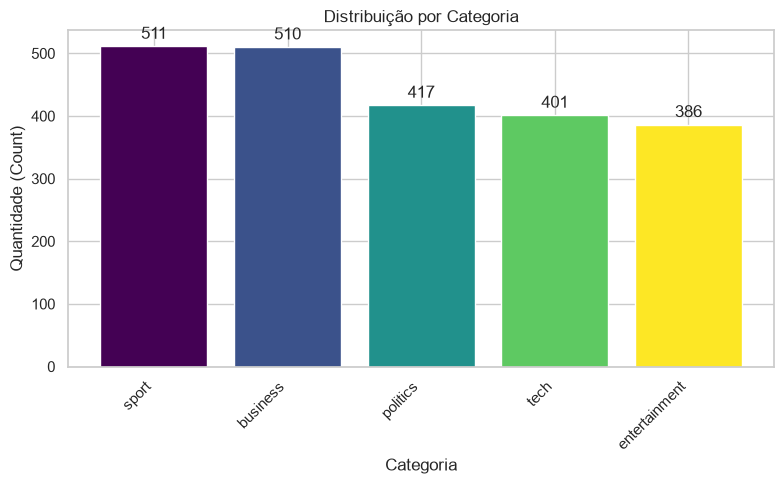

✔ Gráfico salvo: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\distribuicao_classes.png


In [53]:
import numpy as np

counts = df["category"].value_counts()
categories = counts.index
values = counts.values

# 2. Gerar as cores da paleta 'viridis' para a quantidade de categorias
cmap = plt.colormaps["viridis"]
colors = cmap(np.linspace(0, 1, len(categories)))

# 3. Criar a figura e plotar as barras
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(categories, values, color=colors)

# 4. Ajustes visuais (rótulos e títulos)
ax.set_xlabel("Categoria")
ax.set_ylabel("Quantidade (Count)")
ax.set_title("Distribuição por Categoria")

# Dica extra: Adiciona os números em cima de cada barra
ax.bar_label(bars, padding=3)

# Rotaciona os rótulos do eixo X se forem longos
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Salvar figura
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
dist_fig_path = FIGURES_DIR / "distribuicao_classes.png"
plt.savefig(dist_fig_path, dpi=300)
plt.show()
print(f"✔ Gráfico salvo: {dist_fig_path}")


#### Boxplot de Comprimento em Palavras por Categoria

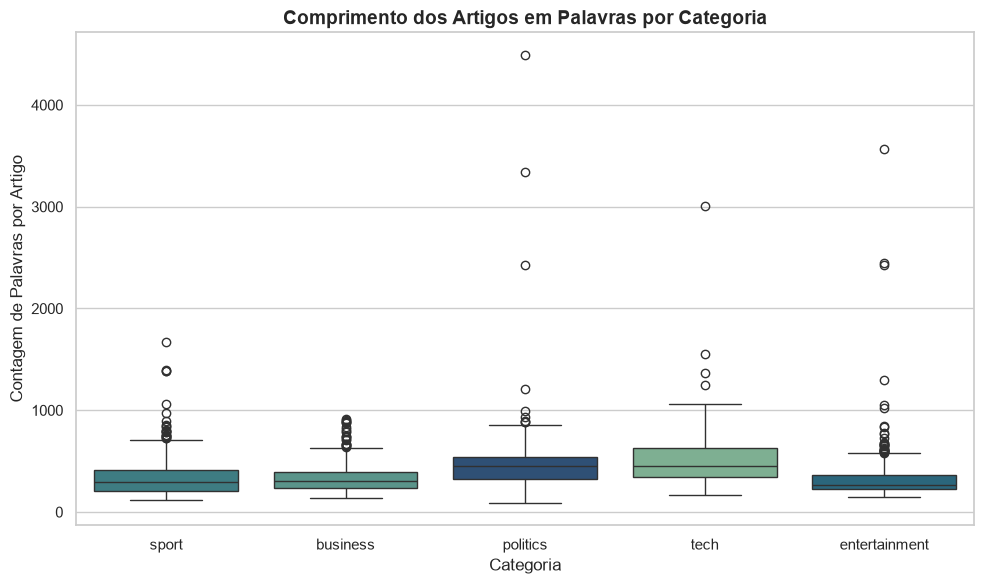

✔ Gráfico salvo: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\tamanho_artigos_por_classe.png


In [54]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="category",
    y="word_count",
    order=df["category"].value_counts().index,
    palette="crest",
    hue="category",
    legend=False
)
plt.title("Comprimento dos Artigos em Palavras por Categoria", fontsize=14, weight="bold")
plt.xlabel("Categoria", fontsize=12)
plt.ylabel("Contagem de Palavras por Artigo", fontsize=12)
plt.tight_layout()

# Salvar figura
boxplot_fig_path = FIGURES_DIR / "tamanho_artigos_por_classe.png"
plt.savefig(boxplot_fig_path, dpi=300)
plt.show()
print(f"✔ Gráfico salvo: {boxplot_fig_path}")


#### Wordcloud de cada categoria

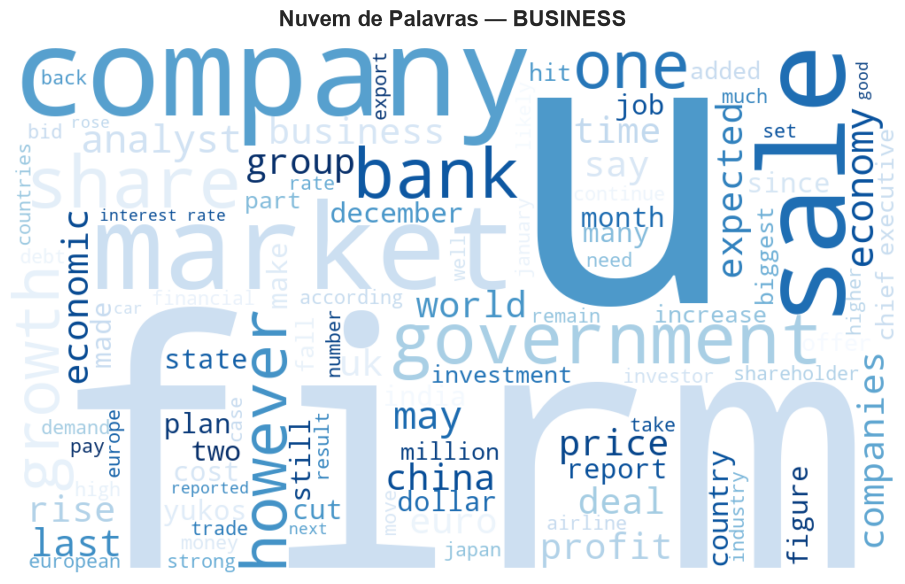

✔ Salva: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\wordcloud_business.png


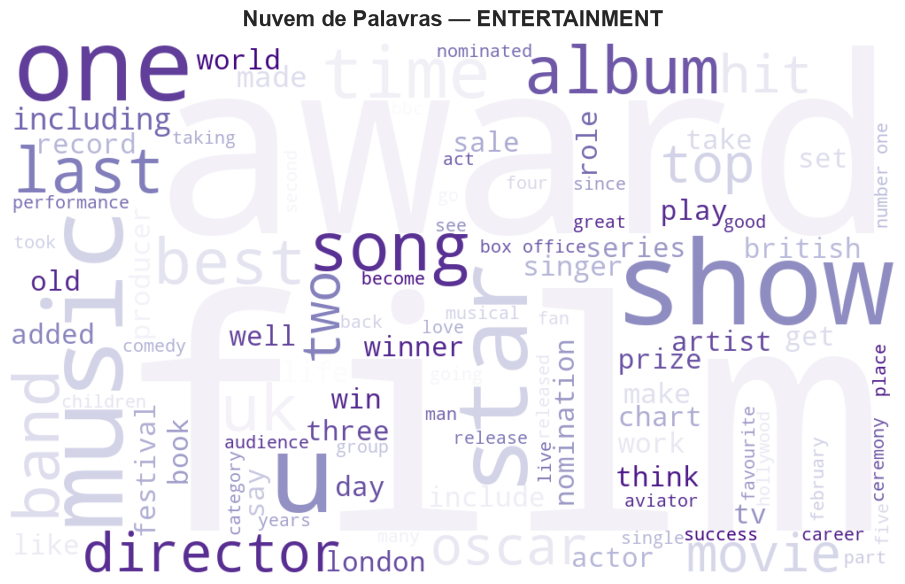

✔ Salva: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\wordcloud_entertainment.png


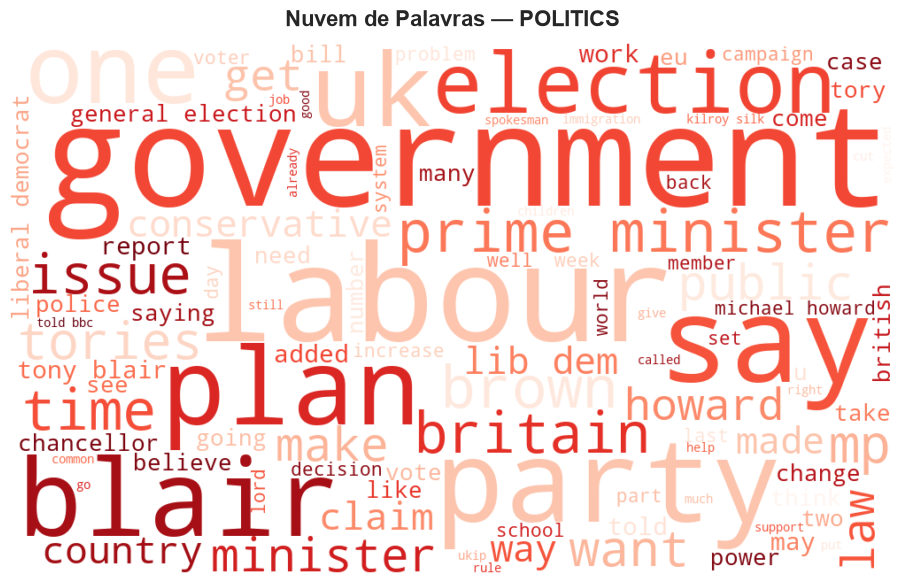

✔ Salva: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\wordcloud_politics.png


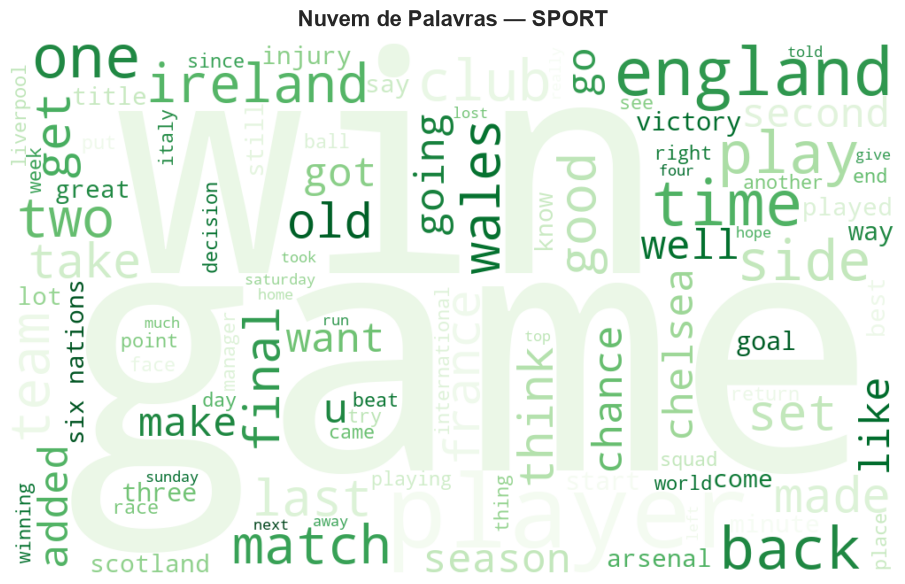

✔ Salva: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\wordcloud_sport.png


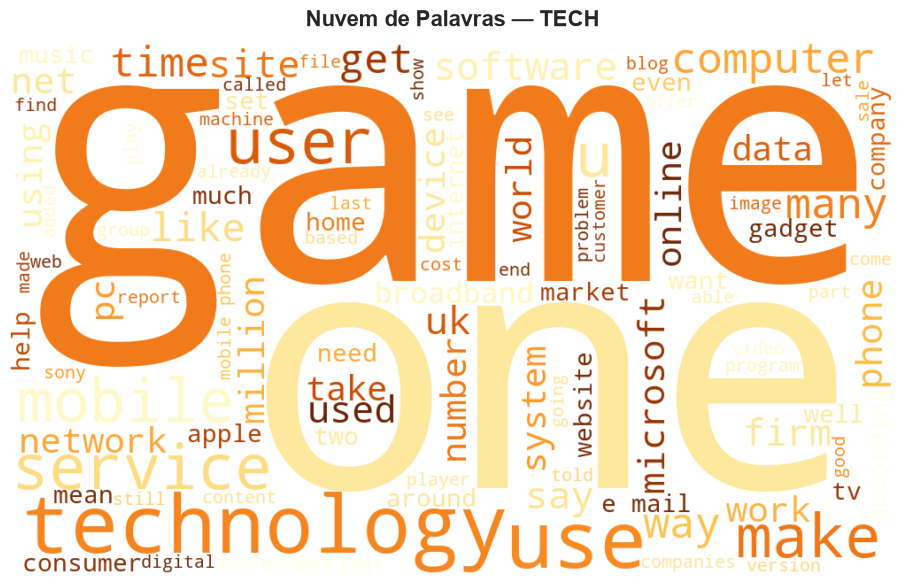

✔ Salva: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\wordcloud_tech.png


In [55]:
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# 1. Download do corpus de stopwords do NLTK (executa silenciosamente se já baixado)
nltk.download("stopwords", quiet=True)
nltk_stopwords = set(stopwords.words("english"))

# 2. Stopwords contextuais adicionais para notícias da BBC
extra_stopwords = {"said", "mr", "year", "people", "would", "new", "also", "could", "first"}
stopwords_set = nltk_stopwords.union(extra_stopwords)

categories = sorted(df["category"].unique())
colormaps = {
    "business": "Blues",
    "entertainment": "Purples",
    "politics": "Reds",
    "sport": "Greens",
    "tech": "YlOrBr",
}

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Gera e exibe cada nuvem individualmente para inspeção detalhada
for category in categories:
    subset_text = " ".join(df[df["category"] == category]["text"].astype(str))
    wc = WordCloud(
        width=1000,
        height=600,
        background_color="white",
        colormap=colormaps.get(category, "viridis"),
        stopwords=stopwords_set,
        max_words=100,
        random_state=42,
    ).generate(subset_text)

    plt.figure(figsize=(10, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.title(f"Nuvem de Palavras — {category.upper()}", fontsize=16, weight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()

    # Salva individualmente
    ind_path = FIGURES_DIR / f"wordcloud_{category}.png"
    plt.savefig(ind_path, dpi=300)
    plt.show()
    print(f"✔ Salva: {ind_path}")


#### Wordcloud de comparação entre todas as categorias

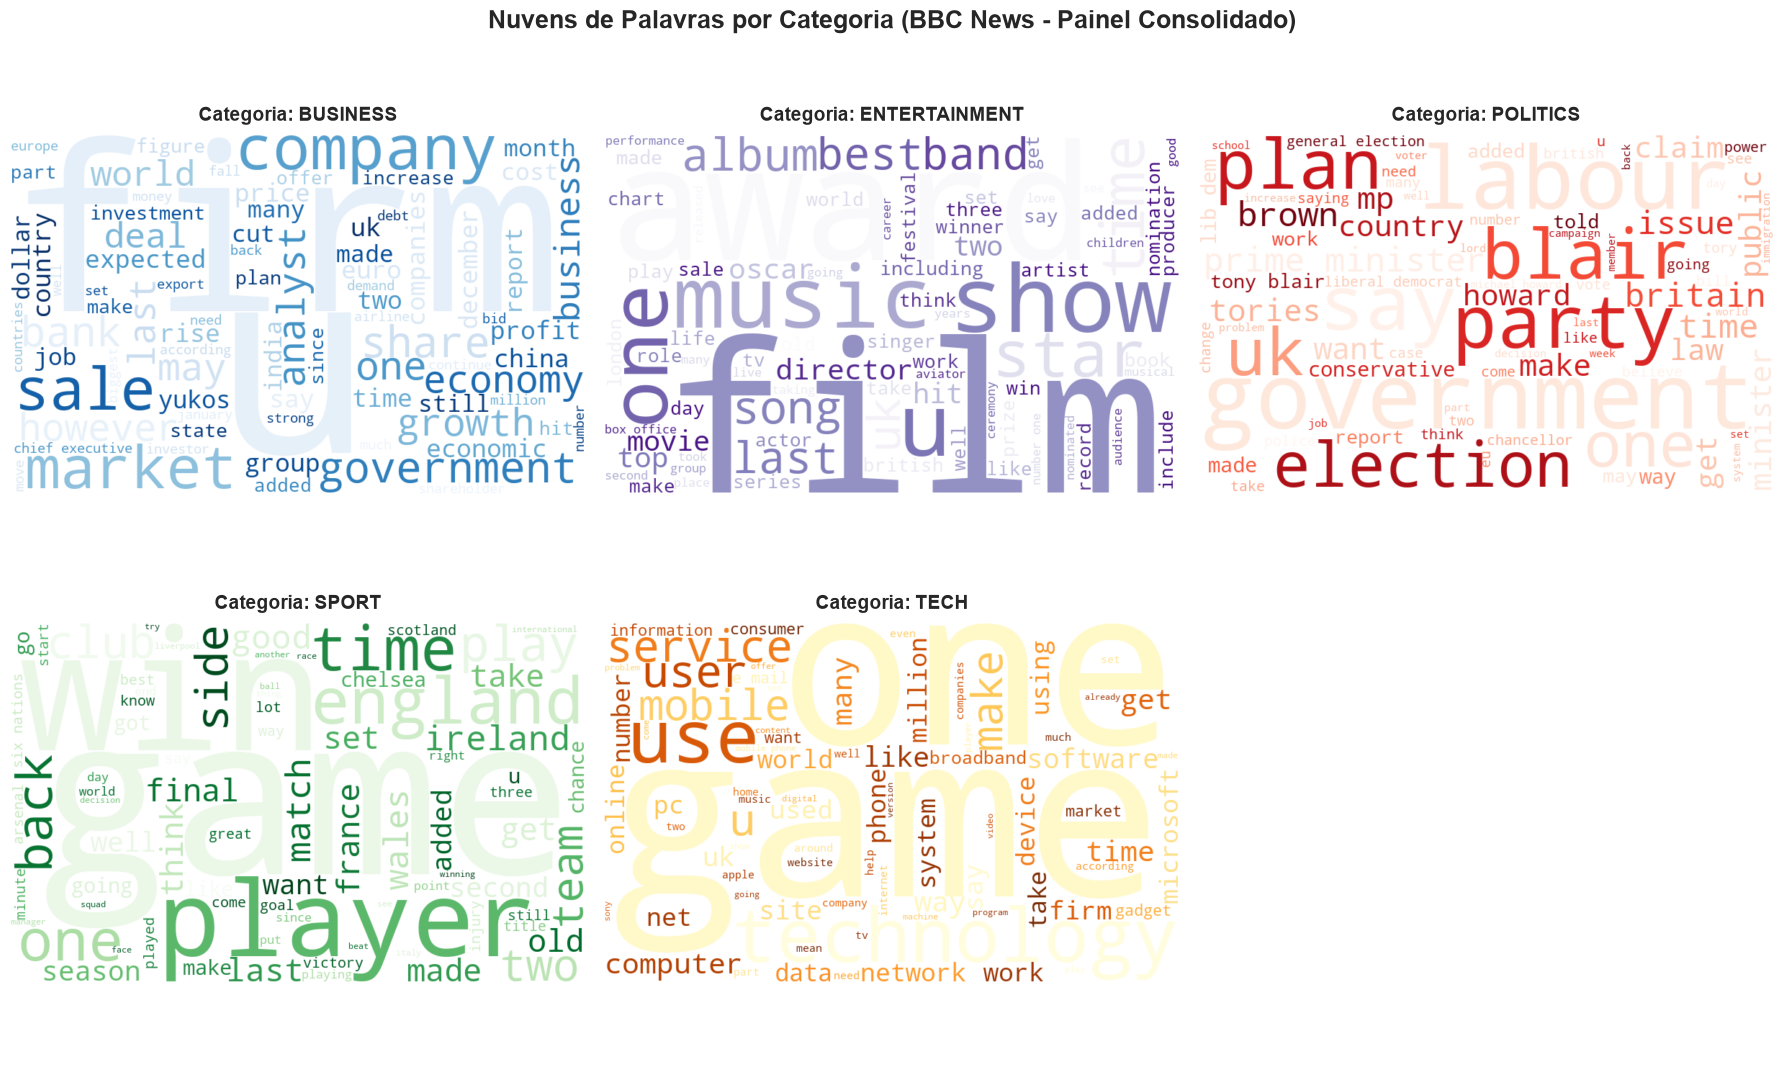

✔ Painel consolidado salvo: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\wordclouds_por_categoria.png


In [56]:
# Painel comparativo 2x3 reunindo todas as categorias lado a lado
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, category in enumerate(categories):
    subset_text = " ".join(df[df["category"] == category]["text"].astype(str))
    wc = WordCloud(
        width=800,
        height=500,
        background_color="white",
        colormap=colormaps.get(category, "viridis"),
        stopwords=stopwords_set,
        max_words=80,
        random_state=42,
    ).generate(subset_text)

    axes[idx].imshow(wc, interpolation="bilinear")
    axes[idx].set_title(f"Categoria: {category.upper()}", fontsize=14, weight="bold", pad=10)
    axes[idx].axis("off")

# Desativa o último eixo vazio (5 categorias em grid 2x3)
axes[5].axis("off")

plt.suptitle("Nuvens de Palavras por Categoria (BBC News - Painel Consolidado)", fontsize=18, weight="bold", y=0.98)
plt.tight_layout()

# Salva o painel e exibe
painel_path = FIGURES_DIR / "wordclouds_por_categoria.png"
plt.savefig(painel_path, dpi=300)
plt.show()
print(f"✔ Painel consolidado salvo: {painel_path}")


#### Gráfico de Barras das Top 10 Palavras por Categoria (Vetorização com CountVectorizer)

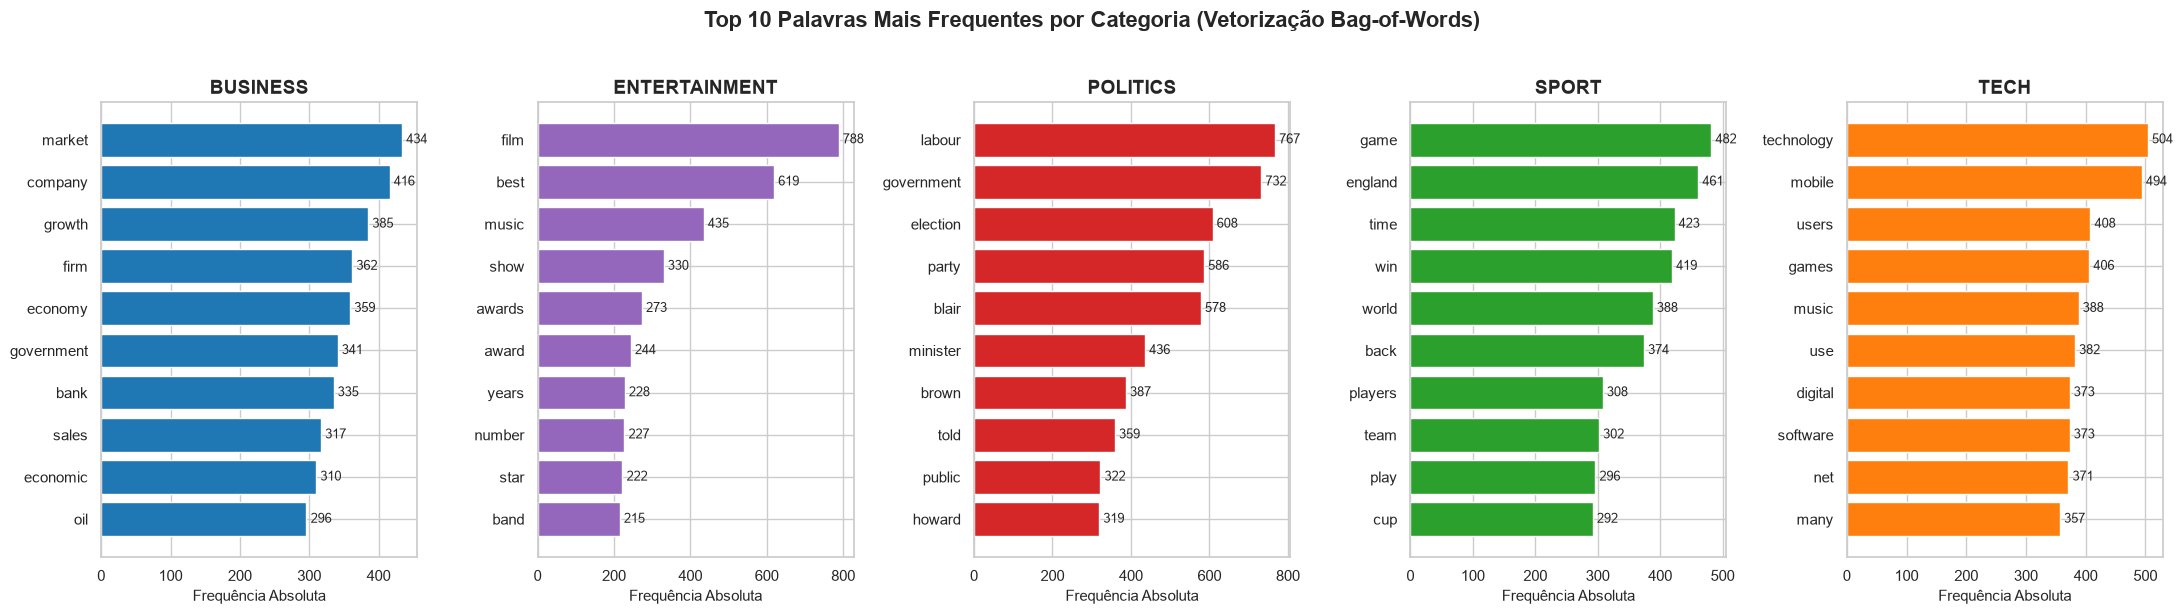

✔ Gráfico de barras salvo: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\top_palavras_por_categoria.png


In [57]:
from sklearn.feature_extraction.text import CountVectorizer

nltk_stopwords = list(stopwords.words("english"))
extra_stopwords = ["said", "mr", "year", "people", "would", "new", "also", "could", "first", "one", "two", "last"]
all_stopwords = nltk_stopwords + extra_stopwords

colormaps = {
    "business": "#1f77b4",
    "entertainment": "#9467bd",
    "politics": "#d62728",
    "sport": "#2ca02c",
    "tech": "#ff7f0e",
}

fig, axes = plt.subplots(1, 5, figsize=(22, 6), sharey=False)

for ax, category in zip(axes, categories):
    cat_texts = df[df["category"] == category]["text"]
    vectorizer = CountVectorizer(
        stop_words=all_stopwords,
        token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
    )
    X = vectorizer.fit_transform(cat_texts)

    # Frequência absoluta somada de cada palavra na categoria
    counts = X.sum(axis=0).A1
    words = vectorizer.get_feature_names_out()

    # Seleciona as 10 palavras mais frequentes
    top_indices = counts.argsort()[-10:]
    top_words = words[top_indices]
    top_counts = counts[top_indices]

    bars = ax.barh(top_words, top_counts, color=colormaps.get(category, "teal"))
    ax.set_title(category.upper(), fontsize=14, weight="bold")
    ax.set_xlabel("Frequência Absoluta", fontsize=11)
    ax.bar_label(bars, padding=3, fontsize=9)

plt.suptitle("Top 10 Palavras Mais Frequentes por Categoria (Vetorização Bag-of-Words)", fontsize=16, weight="bold", y=1.02)
plt.tight_layout()

top_words_fig = FIGURES_DIR / "top_palavras_por_categoria.png"
plt.savefig(top_words_fig, dpi=300, bbox_inches="tight")
plt.show()
print(f"✔ Gráfico de barras salvo: {top_words_fig}")
